# 네이버 웹툰 인기순 vs 조회순 분석

데이터: 네이버 웹툰 요일별 목록 API (`order=user` 인기순, `order=view` 조회순), 2026-10-29 수집

## 1. 준비

In [1]:
import json
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from scipy import stats

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

BASE = Path(".")
DAYS = ["MONDAY", "TUESDAY", "WEDNESDAY", "THURSDAY", "FRIDAY", "SATURDAY", "SUNDAY"]
DAY_KO = dict(zip(DAYS, "월화수목금토일"))

## 2. 데이터 불러오기

In [2]:
# 근거: API 응답의 리스트 순서가 곧 요일 내 순위. 조회수(viewCount)는 대부분 0으로 가려져 있어 순위로 분석
def load(order):
    raw = json.loads((BASE / f"raw_{order}.json").read_text(encoding="utf-8"))
    return pd.DataFrame([
        {"day": day, "titleId": x["titleId"], "titleName": x["titleName"],
         "new": x["new"], "rest": x["rest"], f"rank_{order}": i}
        for day, items in raw["titleListMap"].items() for i, x in enumerate(items, 1)
    ])

pop, view = load("user"), load("view")
df = pop.merge(view[["day", "titleId", "rank_view"]], on=["day", "titleId"]).rename(columns={"rank_user": "rank_pop"})

# 근거: 요일마다 작품 수가 달라(116~136편) 0~1 백분위 순위로 정규화 (0 = 1위)
df["n"] = df.groupby("day")["titleId"].transform("count")
df["pct_pop"] = (df["rank_pop"] - 1) / (df["n"] - 1)
df["pct_view"] = (df["rank_view"] - 1) / (df["n"] - 1)
df["gap"] = df["rank_view"] - df["rank_pop"]  # +면 인기순이 더 높음
df["day_ko"] = df["day"].map(DAY_KO)
df.to_csv(BASE / "webtoon_rank_merged.csv", index=False, encoding="utf-8-sig")
print(f"작품 {len(df)}편 (요일 중복 포함)")

작품 846편 (요일 중복 포함)


## 3. 요일별 상관관계

In [3]:
rows = []
for day in DAYS:
    g = df[df["day"] == day]
    rows.append({
        "요일": DAY_KO[day], "작품수": len(g),
        "Spearman": round(stats.spearmanr(g["rank_pop"], g["rank_view"])[0], 3),
        "Kendall": round(stats.kendalltau(g["rank_pop"], g["rank_view"])[0], 3),
        "Top10 겹침": len(set(g.nsmallest(10, "rank_pop").titleId) & set(g.nsmallest(10, "rank_view").titleId)),
    })
by_day = pd.DataFrame(rows)
by_day

,요일,작품수,Spearman,Kendall,Top10 겹침
0,월,124,0.952,0.825,8
1,화,120,0.934,0.804,6
2,수,116,0.943,0.823,8
3,목,116,0.969,0.864,8
4,금,117,0.943,0.826,8
5,토,136,0.901,0.754,5
6,일,117,0.943,0.810,8


## 4. 전체 상관관계

In [4]:
# 근거: 요일 통합 비교는 백분위 순위로 해야 요일별 작품 수 차이가 사라짐
rho_all, _ = stats.spearmanr(df["pct_pop"], df["pct_view"])
tau_all, _ = stats.kendalltau(df["pct_pop"], df["pct_view"])
print(f"Spearman ρ = {rho_all:.3f}, Kendall τ = {tau_all:.3f}")

Spearman ρ = 0.940, Kendall τ = 0.808


> 모든 요일 ρ ≥ 0.90, 전체 ρ = 0.94 → 두 순위는 거의 같은 순서

## 5. 순위 구간별 일치도

In [5]:
# 근거: 전체 상관이 높아도 특정 구간에서만 엇갈릴 수 있어 구간을 나눠 확인
bands = []
for lo, hi, name in [(0, .2, "상위 20%"), (.2, .5, "20~50%"), (.5, 1.01, "하위 50%")]:
    g = df[(df["pct_pop"] >= lo) & (df["pct_pop"] < hi)]
    bands.append({"구간": name, "작품수": len(g), "Spearman": round(stats.spearmanr(g["pct_pop"], g["pct_view"])[0], 3)})
pd.DataFrame(bands)

,구간,작품수,Spearman
0,상위 20%,170,0.844
1,20~50%,252,0.682
2,하위 50%,424,0.807


> 중위권(20~50%)에서 가장 많이 엇갈림 (ρ 0.68)

## 6. 두 순위가 크게 갈리는 작품

In [6]:
cols = ["day_ko", "titleName", "rank_pop", "rank_view", "gap", "new", "rest"]
pd.concat([df.nsmallest(5, "gap")[cols], df.nlargest(5, "gap")[cols]])  # 위 5개: 조회순 >> 인기순, 아래 5개: 인기순 >> 조회순

,day_ko,titleName,rank_pop,rank_view,gap,new,rest
728,토,아사,136,43,-93,False,False
560,금,몽홀,85,5,-80,False,True
181,화,윌유메리미,66,6,-60,False,False
82,수,하렘의 남자들,83,30,-53,False,False
698,토,멸망한 세계의 취사병,106,57,-49,False,False
163,화,끓는 점,48,100,52,True,False
634,토,메이드,42,83,41,True,False
636,토,주식토피아,44,85,41,True,False
685,토,상향혼 컨설팅,93,131,38,True,False
182,화,시골 다방에 요괴들이 와요,67,103,36,True,False


## 7. 순위 차이의 원인: 연재 기간

In [7]:
# 근거: 6단계에서 조회순 우위 = 오래된·휴재작, 인기순 우위 = 신작으로 보여 수치로 검증 (titleId가 클수록 최신)
df["pct_gap"] = df["pct_view"] - df["pct_pop"]
r, p = stats.spearmanr(df["titleId"], df["pct_gap"])
print(f"titleId vs 순위차: ρ = {r:.3f} (p = {p:.1e})")
print(df.groupby("new")["pct_gap"].agg(["count", "mean"]).round(3))
print(df.groupby("rest")["pct_gap"].agg(["count", "mean"]).round(3))

titleId vs 순위차: ρ = 0.424 (p = 2.9e-38)
       count   mean
new                
False    782 -0.009
True      64  0.106
       count   mean
rest               
False    802  0.005
True      44 -0.084


> 신작은 인기순이 +10.6%p, 휴재작은 조회순이 +8.4%p 높음 → 조회순은 누적, 인기순은 최근 반응을 반영 (추정)

## 8. 시각화

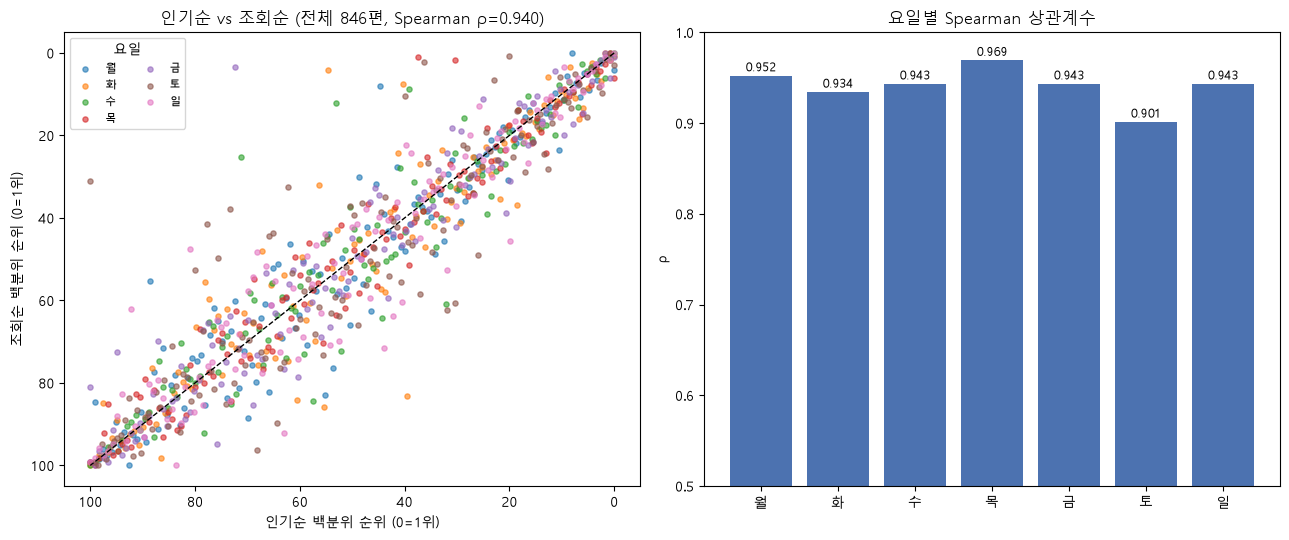

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for day in DAYS:
    g = df[df["day"] == day]
    axes[0].scatter(g["pct_pop"] * 100, g["pct_view"] * 100, s=14, alpha=.6, label=DAY_KO[day])
axes[0].plot([0, 100], [0, 100], "k--", lw=1)
axes[0].set(xlabel="인기순 백분위 순위 (0=1위)", ylabel="조회순 백분위 순위 (0=1위)",
            title=f"인기순 vs 조회순 (전체 {len(df)}편, Spearman ρ={rho_all:.3f})")
axes[0].invert_xaxis(); axes[0].invert_yaxis()
axes[0].legend(title="요일", fontsize=8, ncol=2)
axes[1].bar(by_day["요일"], by_day["Spearman"], color="#4C72B0")
for i, v in enumerate(by_day["Spearman"]):
    axes[1].text(i, v + .005, f"{v:.3f}", ha="center", fontsize=9)
axes[1].set(ylim=(.5, 1), title="요일별 Spearman 상관계수", ylabel="ρ")
plt.tight_layout()
plt.savefig(BASE / "rank_corr.png", dpi=130)
plt.show()

## 9. 작품 정보·회차 별점 수집

In [9]:
# 근거: 체급(관심 수)과 회차별 별점은 요일 목록에 없어 작품별 API로 추가 수집. 첫 실행 약 1시간이라 cache/에 저장
API = "https://comic.naver.com/api/article"
CACHE = BASE / "cache"
CACHE.mkdir(exist_ok=True)

def get_json(url, params):
    for attempt in range(3):
        try:
            r = requests.get(url, params=params, headers={"User-Agent": "Mozilla/5.0"}, timeout=10)
            if r.status_code == 401:  # 성인 작품은 로그인 필요 → 회차 수집 생략
                return None
            r.raise_for_status()
            time.sleep(0.15)  # 서버 부담 완화
            return r.json()
        except requests.RequestException:
            time.sleep(2 * (attempt + 1))
    raise RuntimeError(f"요청 실패: {url} {params}")

def collect(title_id):
    path = CACHE / f"{title_id}.json"
    if path.exists():
        return json.loads(path.read_text(encoding="utf-8"))
    info = get_json(f"{API}/list/info", {"titleId": title_id})
    episodes, page = [], 1
    while True:  # 회차 목록은 20화씩 페이지로 나뉨
        d = get_json(f"{API}/list", {"titleId": title_id, "page": page, "sort": "ASC"})
        if d is None:
            break
        episodes += [{"no": a["no"], "starScore": a["starScore"], "date": a["serviceDateDescription"]} for a in d["articleList"]]
        if page >= d["pageInfo"]["totalPages"]:
            break
        page += 1
    data = {"titleId": int(title_id), "favoriteCount": info["favoriteCount"],
            "genres": [t["tagName"] for t in info["curationTagList"] if t["curationType"].startswith("GENRE")],
            "tags": [t["tagName"] for t in info["curationTagList"] if t["curationType"] == "CUSTOM_TAG"],
            "age": info["age"]["type"], "episodes": episodes}
    path.write_text(json.dumps(data, ensure_ascii=False), encoding="utf-8")
    return data

details = [collect(tid) for tid in df["titleId"].unique()]
info = pd.DataFrame([{"titleId": d["titleId"], "favoriteCount": d["favoriteCount"],
                      "genre": d["genres"][0] if d["genres"] else "기타"} for d in details])
df = df.merge(info, on="titleId", how="left")
print(f"작품 {len(details)}편, 회차 {sum(len(d['episodes']) for d in details):,}개")

작품 820편, 회차 65,265개


## 10. 관심 수와 순위

In [10]:
# 근거: 별점(ρ 0.16)은 순위를 설명하지 못해, 작품 체급을 나타낼 다른 지표로 관심 등록 수를 확인
print(f"관심 수 vs 인기순 ρ = {-stats.spearmanr(df['favoriteCount'], df['pct_pop'])[0]:.3f}")
print(f"관심 수 vs 조회순 ρ = {-stats.spearmanr(df['favoriteCount'], df['pct_view'])[0]:.3f}")

관심 수 vs 인기순 ρ = 0.677
관심 수 vs 조회순 ρ = 0.798


> 관심 수가 순위를 가장 잘 설명함 (별점의 4배 이상)

## 11. 같은 작품, 다른 요일: 토요일 효과

In [11]:
# 근거: 여러 요일 연재작은 작품이 같고 요일만 달라, 요일별 순위 차이가 곧 요일 효과
multi = df[df.groupby("titleId")["day"].transform("count") > 1].copy()
multi["diff"] = multi["pct_pop"] - multi.groupby("titleId")["pct_pop"].transform("mean")  # 그 작품 평소 순위 대비 차이

sat = multi[multi["day"] == "SATURDAY"]["diff"]
print(f"여러 요일 연재작 {multi['titleId'].nunique()}편 중 토요일 연재 {len(sat)}편")
print("토요일 순위 - 평소 순위(%p):", (sat * 100).round(1).tolist())
print(f"윌콕슨 p = {stats.wilcoxon(sat).pvalue:.4f}")  # 표본이 작아 비모수 검정
print("장르:", multi.drop_duplicates("titleId")["genre"].value_counts().to_dict())

여러 요일 연재작 25편 중 토요일 연재 9편
토요일 순위 - 평소 순위(%p): [-3.2, -4.8, -3.2, -6.2, -9.2, -5.3, -4.9, -6.0, -4.0]
윌콕슨 p = 0.0039
장르: {'일상': 14, '로맨스': 4, '드라마': 3, '개그': 2, '판타지': 2}


> 토요일 연재 9편 모두 토요일 순위가 평소보다 높음 (평균 5.2%p, p = 0.004). 단 25편 중 14편이 일상툰

## 12. 웹툰 수명 곡선

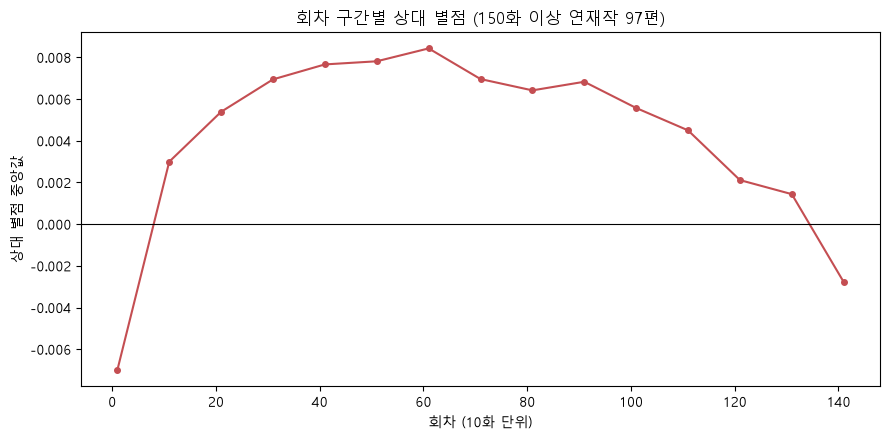

In [12]:
# 근거: 미리보기(유료) 회차는 별점 참여자가 적어 값이 불안정 → 무료 회차만 사용
ep = pd.DataFrame([{"titleId": d["titleId"], "ep": i, "star": e["starScore"], "date": e["date"]}
                   for d in details for i, e in enumerate(d["episodes"], 1)])
free = ep[~ep["date"].str.contains("무료")].copy()

# 근거: 작품마다 별점 수준이 달라, 그 작품 중앙값을 뺀 상대 별점으로 비교
free["rel_star"] = free["star"] - free.groupby("titleId")["star"].transform("median")
free["n_eps"] = free.groupby("titleId")["ep"].transform("max")
free["ep_bin"] = ((free["ep"] - 1) // 10) * 10 + 1

# 근거: 뒤 회차일수록 살아남은 인기작만 남는 생존자 편향 → 150화 이상 작품만으로 1~150화 비교
long_titles = free[(free["n_eps"] >= 150) & (free["ep"] <= 150)]
curve = long_titles.groupby("ep_bin")["rel_star"].median()

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(curve.index, curve.values, marker="o", ms=4, color="#C44E52")
ax.axhline(0, color="k", lw=0.8)
ax.set(title=f"회차 구간별 상대 별점 (150화 이상 연재작 {long_titles['titleId'].nunique()}편)",
       xlabel="회차 (10화 단위)", ylabel="상대 별점 중앙값")
plt.tight_layout()
plt.savefig(BASE / "lifecycle_curve.png", dpi=130)
plt.show()

In [13]:
# 근거: 중앙값 곡선은 일부 작품이 끌고 갈 수 있어, 작품마다 구간별 값을 짝지어 검정
phases = long_titles.groupby("titleId").apply(lambda g: pd.Series({
    "초반": g[g["ep"] <= 10]["rel_star"].median(),
    "중반": g[(g["ep"] > 40) & (g["ep"] <= 100)]["rel_star"].median(),
    "후반": g[g["ep"] > 110]["rel_star"].median(),
}), include_groups=False)
print(f"중반 > 초반: {(phases['중반'] > phases['초반']).mean():.0%} (p = {stats.wilcoxon(phases['중반'], phases['초반']).pvalue:.1e})")
print(f"후반 < 중반: {(phases['후반'] < phases['중반']).mean():.0%} (p = {stats.wilcoxon(phases['후반'], phases['중반']).pvalue:.1e})")

중반 > 초반: 79% (p = 2.4e-07)
후반 < 중반: 77% (p = 1.5e-06)


> 초반 최저 → 40~100화 정점 → 110화 이후 하락. 장편의 약 80%에서 확인 (차이는 약 0.015점으로 작음)

## 결론

1. 인기순과 조회순은 매우 강하게 일치 (ρ = 0.94), 중위권에서 가장 많이 엇갈림
2. 차이의 원인은 연재 기간: 신작은 인기순, 오래된·휴재작은 조회순이 더 높음
3. 순위를 가장 잘 설명하는 지표는 별점이 아닌 관심 등록 수 (ρ 0.68 / 0.80)
4. 여러 요일 연재작은 토요일에 순위가 더 높음 (9편 모두, p = 0.004)
5. 장편 웹툰 별점은 40~100화에 정점, 110화 이후 하락 ('100화 고비')